Imported necessary libraries for project

In [53]:
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt

Opened files to be read as text

In [54]:
principles_economy = open("textfiles/raw_files/principles_political_economy.txt").read()
principles_psychology = open("textfiles/raw_files/principles_psychology.txt").read()

Manually deleted all bibliographys, table of contents, licenses, and footnotes. Then Created a dictionary to allow for looping through both files to reduce redundant code

In [55]:
texts = {
         "principles_economy": principles_economy,
    "principles_psychology": principles_psychology,
        }

Patterns to remove spaces and special characters/punctuation

In [56]:
large_space_pattern = re.compile(r'\s+')
punctuation_pattern = re.compile(r'[’‘“”\"\'\!.,\-—_\/\:\;\?()\[\]{}*&@$%§0-9]')

Applied patterns to all texts and stored all words in one series

In [57]:
words = pd.Series()
for name, text in texts.items():
    text = text.lower()
    text = large_space_pattern.sub(' ', text)
    text = punctuation_pattern.sub('', text)
    word_series = pd.Series(text.split(),name='labels')
    words = pd.concat([words, word_series])
    # open(f"/Users/carsonchan/Documents/Schoolwork F2026/CS 24200/Project1/textfiles/cleaned_files/{name}_cleaned.txt", "w").write(text)

Removed duplicates and stored result in a new Series

In [58]:
unique_words = words.drop_duplicates(keep='first')

List of stopwords to remove (sourced from Claude)

In [59]:
stopwords = [
    "a", "about", "above", "after", "again", "against", "all", "am", "an", "and",
    "any", "are", "arent", "as", "at", "be", "because", "been", "before", "being",
    "below", "between", "both", "but", "by", "can", "cant", "cannot", "could",
    "couldnt", "did", "didnt", "do", "does", "doesnt", "doing", "dont", "down",
    "during", "each", "few", "for", "from", "further", "had", "hadnt", "has",
    "hasnt", "have", "havent", "having", "he", "hed", "hell", "hes", "her", "here",
    "heres", "hers", "herself", "him", "himself", "his", "how", "hows", "i", "id",
    "ill", "im", "ive", "if", "in", "into", "is", "isnt", "it", "its", "itself",
    "lets", "may", "me", "more", "most", "must", "my", "myself", "no", "nor", "not",
    "of", "off", "on", "once", "only", "or", "other", "ought", "our", "ours",
    "ourselves", "out", "over", "own", "same", "shant", "she", "shed", "shell",
    "shes", "should", "shouldnt", "so", "some", "such", "than", "that", "thats",
    "the", "their", "theirs", "them", "themselves", "then", "there", "theres",
    "these", "they", "theyd", "theyll", "theyre", "theyve", "this", "those",
    "through", "to", "too", "under", "until", "up", "very", "was", "wasnt", "we",
    "wed", "well", "were", "werent", "weve", "what", "whats", "when", "whens",
    "where", "wheres", "which", "while", "who", "whos", "whom", "why", "whys",
    "will", "with", "wont", "would", "wouldnt", "you", "youd", "youll", "youre",
    "youve", "your", "yours", "yourself", "yourselves", "one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"
]

In [60]:
len(unique_words)

18669

In [61]:
unique_words = unique_words[~unique_words.isin(stopwords)]

In [62]:
len(unique_words)

18512

Initialize the series of words for the econ text

In [63]:
econ_text = texts['principles_economy'].lower()
econ_text = large_space_pattern.sub(' ', econ_text)
econ_text = punctuation_pattern.sub('', econ_text)
econ_df = (pd.Series(econ_text.split(), name='economy'))
counts_econ = unique_words.map(econ_df.value_counts())
counts_econ


0          74.0
4          16.0
6         626.0
13        792.0
15          9.0
          ...  
269290      NaN
269291      NaN
269292      NaN
269293      NaN
269296      NaN
Length: 18512, dtype: float64

Initialize word series for psychology text

In [64]:
psycho_text = texts['principles_psychology'].lower()
psycho_text = large_space_pattern.sub(' ', psycho_text)
psycho_text = punctuation_pattern.sub('', psycho_text)
psycho_df = (pd.Series(psycho_text.split(), name = 'psychology'))
counts_psycho = unique_words.map(psycho_df.value_counts())
counts_psycho


0         185.0
4           NaN
6          17.0
13          8.0
15         28.0
          ...  
269290      1.0
269291      1.0
269292      1.0
269293      1.0
269296      1.0
Length: 18512, dtype: float64

Combine their counts of each word in the unique words dataset

In [65]:
total_df = pd.concat([counts_econ, counts_psycho], axis = 1)
total_df.index = unique_words
total_df.columns = ['economy', 'psychology']

total_df

,economy,psychology
chapter,74.0,185.0
requisites,16.0,NaN
production,626.0,17.0
labor,792.0,8.0
appropriate,9.0,28.0
...,...,...
fauths,NaN,1.0
das,NaN,1.0
gedächtniss,NaN,1.0
studie,NaN,1.0


Fix na values by replacing them with 0

In [66]:
total_df.fillna(0, inplace = True)

,economy,psychology
chapter,74.0,185.0
requisites,16.0,0.0
production,626.0,17.0
labor,792.0,8.0
appropriate,9.0,28.0
...,...,...
fauths,0.0,1.0
das,0.0,1.0
gedächtniss,0.0,1.0
studie,0.0,1.0


Get the total sum of words of each column

In [67]:
sums = total_df.sum(axis=0)
sums

economy        90063.0
psychology    126757.0
dtype: float64

Divide each column by its sum to get the Text Frequency dataframe

In [68]:
tf_df = total_df.div(sums, axis = 1)
tf_df

,economy,psychology
chapter,0.000822,0.001459
requisites,0.000178,0.000000
production,0.006951,0.000134
labor,0.008794,0.000063
appropriate,0.000100,0.000221
...,...,...
fauths,0.000000,0.000008
das,0.000000,0.000008
gedächtniss,0.000000,0.000008
studie,0.000000,0.000008


In [69]:
tf_df.sort_values(by=['economy'], ascending = False)

,economy,psychology
capital,0.010482,0.000024
labor,0.008794,0.000063
value,0.007717,0.000245
production,0.006951,0.000134
money,0.006884,0.000039
...,...,...
nonentity,0.000000,0.000032
quibble,0.000000,0.000008
midshipman,0.000000,0.000008
illegitimacy,0.000000,0.000008


Get the IDF by taking dividing the number of documents (2) by 1 + the sum of whether the word appears in either doc, then take the log of that

In [70]:
word_appearances = (total_df > 0).sum(axis = 1)

idf = np.log(4/(1 + word_appearances))
idf.sort_values()

chapter              0.287682
initial              0.287682
presume              0.287682
occupying            0.287682
selfcontradictory    0.287682
                       ...   
phase                0.693147
cast                 0.693147
angular              0.693147
parietal             0.693147
pädagogik            0.693147
Length: 18512, dtype: float64

Multiply the term frequency with the inverse document frequency to get the tfidf dataframe

In [71]:
tfidf = tf_df.mul(idf, axis = 0)
tfidf

,economy,psychology
chapter,0.000236,0.000420
requisites,0.000123,0.000000
production,0.002000,0.000039
labor,0.002530,0.000018
appropriate,0.000029,0.000064
...,...,...
fauths,0.000000,0.000005
das,0.000000,0.000005
gedächtniss,0.000000,0.000005
studie,0.000000,0.000005


Sort highest values of economy

In [72]:
tfidf.sort_values(by = ['economy'], ascending = False)['economy'].head()

capital        0.003015
commodities    0.002678
labor          0.002530
profits        0.002340
value          0.002220
Name: economy, dtype: float64

In [73]:
tfidf.sort_values(by = ['psychology'], ascending = False)['psychology']


consciousness     0.003068
thought           0.001473
memory            0.001427
self              0.001394
mind              0.001391
                    ...   
classtax          0.000000
forbearance       0.000000
workable          0.000000
ministries        0.000000
agriculturists    0.000000
Name: psychology, Length: 18512, dtype: float64

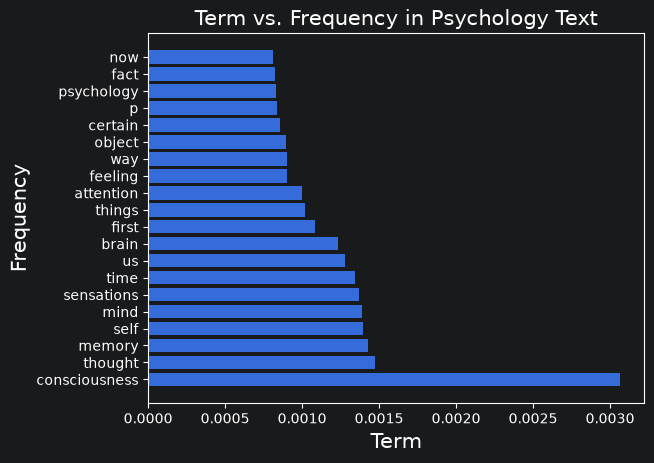

In [74]:
tfidf_psych = tfidf['psychology']
top_psych = tfidf_psych.sort_values(axis=0, ascending = False).head(20)
terms = np.array(top_psych.index)
values = np.array(top_psych.values)
plt.barh(terms,values)
plt.xlabel('Term', fontsize = 15)
plt.ylabel('Frequency', fontsize = 15)
plt.title("Term vs. Frequency in Psychology Text", fontsize = 15)

plt.show()



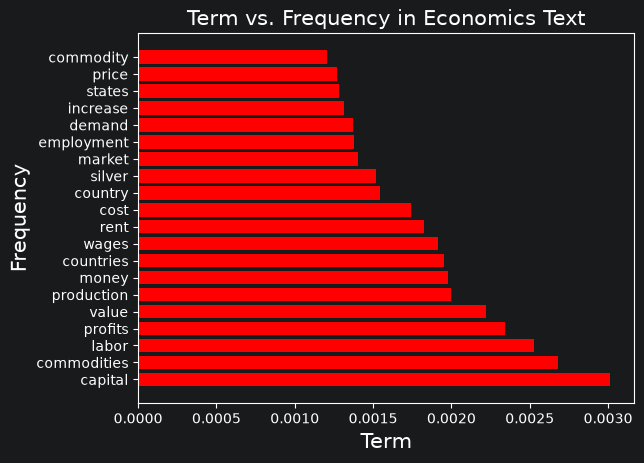

In [75]:
tfidf_econ = tfidf['economy']
top_econ = tfidf_econ.sort_values(axis=0, ascending = False).head(20)
terms = np.array(top_econ.index)
values = np.array(top_econ.values)
plt.barh(terms,values, color = 'red')
plt.xlabel('Term', fontsize = 15)
plt.ylabel('Frequency', fontsize = 15)
plt.title("Term vs. Frequency in Economics Text", fontsize = 15)
plt.show()
plt.show()

